In [2]:
import pandas as pd

df = pd.read_csv("new_data.csv")

print(df.shape)
print(df.head())
print(df.info())
print(df.isnull().sum())

(6362620, 11)
   step      type    amount     nameOrig  oldbalanceOrg  newbalanceOrig  \
0     1   PAYMENT   9839.64  C1231006815       170136.0       160296.36   
1     1   PAYMENT   1864.28  C1666544295        21249.0        19384.72   
2     1  TRANSFER    181.00  C1305486145          181.0            0.00   
3     1  CASH_OUT    181.00   C840083671          181.0            0.00   
4     1   PAYMENT  11668.14  C2048537720        41554.0        29885.86   

      nameDest  oldbalanceDest  newbalanceDest  isFraud  isFlaggedFraud  
0  M1979787155             0.0             0.0        0               0  
1  M2044282225             0.0             0.0        0               0  
2   C553264065             0.0             0.0        1               0  
3    C38997010         21182.0             0.0        1               0  
4  M1230701703             0.0             0.0        0               0  
<class 'pandas.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11

The dataset used was new_data.csv which contains a payment transaction dataset.
There are 6,362,620 rows and 11 columns.
Each row represents a transaction.
The columns are:
step: A time measure
type: Type of payment
amount: The amount
nameOrig: Name of original account holder
oldbalanceOrg: Balance in account before transaction
newbalanceOrig: Balance in account after transaction
nameDest: Name of destination account holder
oldbalanceDest: Balance in account before transaction
newbalanceDest: Balance in account after transaction
isFraud: Target variable (1 = fraud, 0 = not fraud)
There are 3 categorical variables and 8 numerical variables.
No missing values in any of the columns so there was nothing to impute.

In [3]:
# 1. Summary numbers for each numeric column
print(df.describe())

# 2. How many fraud vs not fraud
print(df["isFraud"].value_counts())
print(df["isFraud"].value_counts(normalize=True) * 100)

# 3. How many of each payment type
print(df["type"].value_counts())

# 4. Fraud count by payment type
print(df.groupby("type")["isFraud"].sum())

# 5. Duplicate rows
print("Duplicates:", df.duplicated().sum())

               step        amount  oldbalanceOrg  newbalanceOrig  \
count  6.362620e+06  6.362620e+06   6.362620e+06    6.362620e+06   
mean   2.433972e+02  1.798619e+05   8.338831e+05    8.551137e+05   
std    1.423320e+02  6.038582e+05   2.888243e+06    2.924049e+06   
min    1.000000e+00  0.000000e+00   0.000000e+00    0.000000e+00   
25%    1.560000e+02  1.338957e+04   0.000000e+00    0.000000e+00   
50%    2.390000e+02  7.487194e+04   1.420800e+04    0.000000e+00   
75%    3.350000e+02  2.087215e+05   1.073152e+05    1.442584e+05   
max    7.430000e+02  9.244552e+07   5.958504e+07    4.958504e+07   

       oldbalanceDest  newbalanceDest       isFraud  isFlaggedFraud  
count    6.362620e+06    6.362620e+06  6.362620e+06    6.362620e+06  
mean     1.100702e+06    1.224996e+06  1.290820e-03    2.514687e-06  
std      3.399180e+06    3.674129e+06  3.590480e-02    1.585775e-03  
min      0.000000e+00    0.000000e+00  0.000000e+00    0.000000e+00  
25%      0.000000e+00    0.000000e+00

 The amount column has a value of about 180,000. This mean is much larger than the median of 75,000 and the maximum of about 92 million. Because of this the amount column contains an extreme values that cause a skew in the data. The balance column contains zeros more than half of the newbalanceOrig entries are zero. There are 8,213 frauds compared to 6,354,407 transactions. The fraud ratio is 0.129 percent, which shows a class imbalance. The payment types are: CASH_OUT = 2,237,500; PAYMENT = 2,151,495; CASH_IN = 1,399,284; TRANSFER = 532,909; DEBIT = 41,432. Only TRANSFER (4,097) and CASH_OUT (4,116) have frauds. The other three payment types have zero frauds. IsFlaggedFraud has all zeros with a mean of, about 0.0000025. This means that almost nothing is being flagged by the bank rules. There are no duplicates.

Duplicates: 0


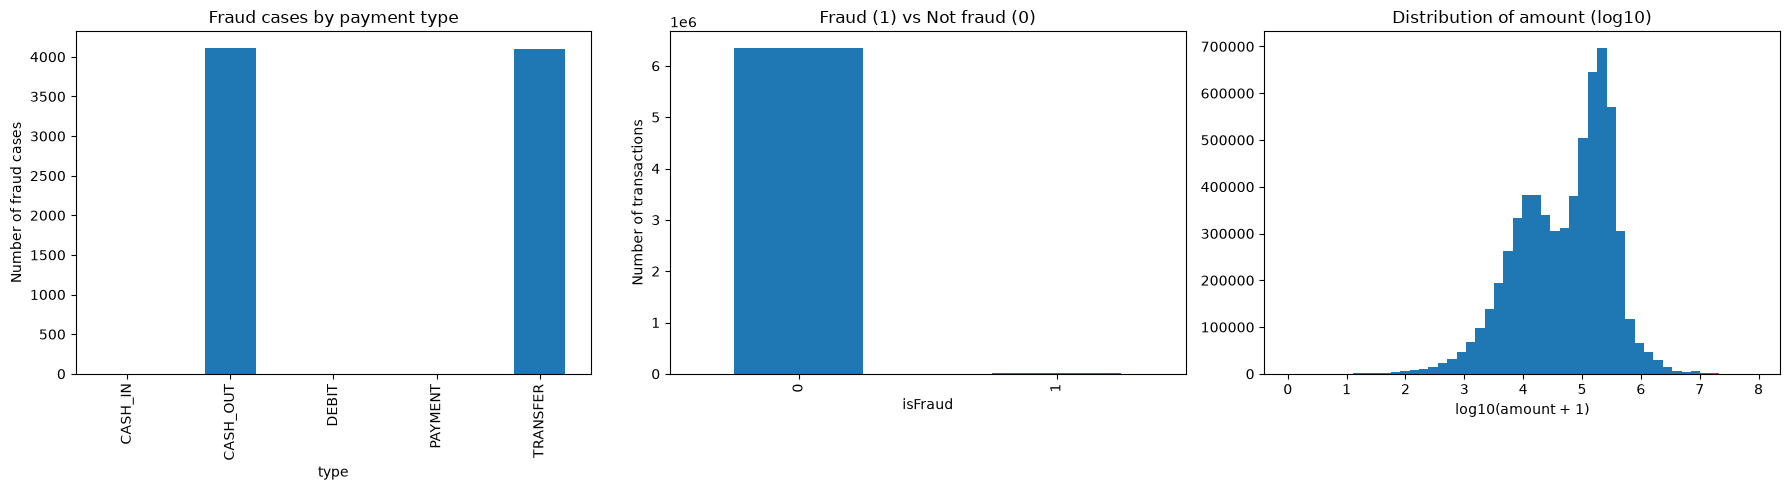

In [4]:
import matplotlib.pyplot as plt
import numpy as np

print("Duplicates:", df.duplicated().sum())

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Chart 1: fraud count by payment type
df.groupby("type")["isFraud"].sum().plot(kind="bar", ax=axes[0])
axes[0].set_title("Fraud cases by payment type")
axes[0].set_ylabel("Number of fraud cases")

# Chart 2: fraud vs not fraud
df["isFraud"].value_counts().plot(kind="bar", ax=axes[1])
axes[1].set_title("Fraud (1) vs Not fraud (0)")
axes[1].set_ylabel("Number of transactions")

# Chart 3: amount distribution (log scale so it is readable)
axes[2].hist(np.log10(df["amount"] + 1), bins=50)
axes[2].set_title("Distribution of amount (log10)")
axes[2].set_xlabel("log10(amount + 1)")

plt.tight_layout()
plt.savefig("eda_charts_1.png")
plt.show()

Chart 1: We can see that only CASH_OUT and TRANSFER have fraud, with approximately 4100 each. CASH_IN, DEBIT and PAYMENT all have 0.
Chart 2: The 0 bar has approximately 6.3million and the 1 bar is too small to notice, showing there is a class imbalance.
Chart 3:
Most of the values are between 10^4 and 10^6 (between 10,000 and 1 million).
The main peak is between 10^5 and 10^5.5 (between 100,000 and 300,000).
There is another smaller peak between near 10^4 (between 10,000 and 20,000).
There are very few extremely large values, larger than 10^7. These are the outliers which made the average skew.
Overall, we can see that the amount is very skewed, so taking the log could be useful for some models. Also, since only 2 types have fraud it means that type is an important feature.

             count          mean           std   min         25%        50%  \
isFraud                                                                       
0        6354407.0  1.781970e+05  5.962370e+05  0.01   13368.395   74684.72   
1           8213.0  1.467967e+06  2.404253e+06  0.00  127091.330  441423.44   

                75%          max  
isFraud                           
0         208364.76  92445516.64  
1        1517771.48  10000000.00  
type
CASH_IN     0.000000
CASH_OUT    0.183955
DEBIT       0.000000
PAYMENT     0.000000
TRANSFER    0.768799
Name: isFraud, dtype: float64


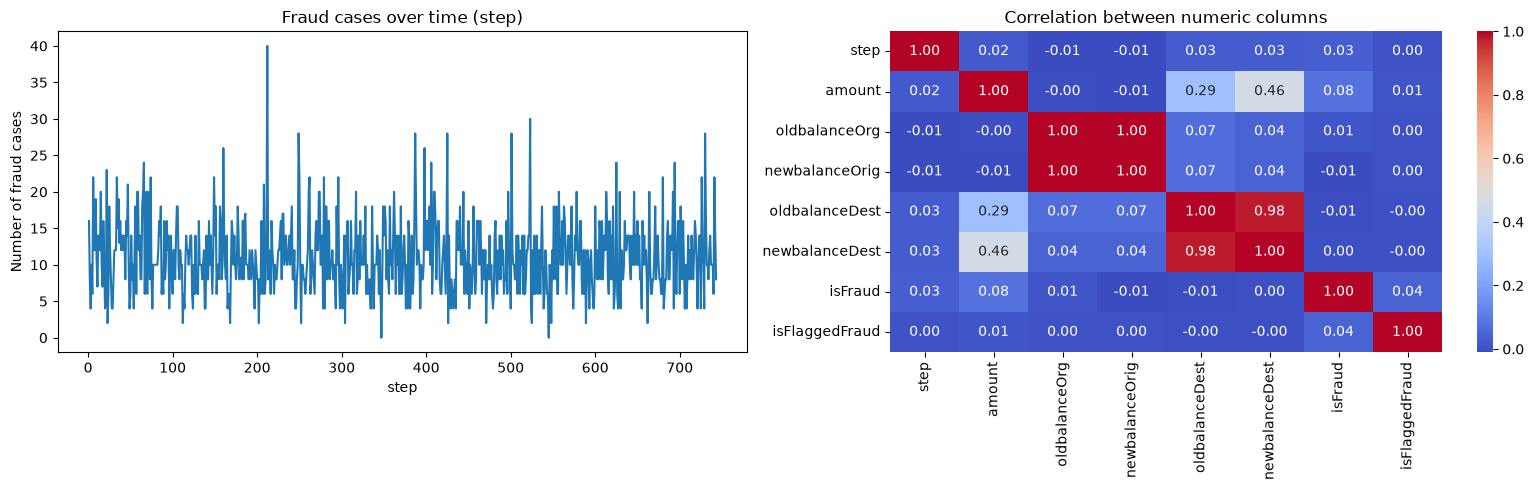

In [5]:
# 1. Amount: fraud vs not fraud
print(df.groupby("isFraud")["amount"].describe())

# 2. Fraud rate (%) inside each payment type
print(df.groupby("type")["isFraud"].mean() * 100)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Chart 4: fraud cases over time
df.groupby("step")["isFraud"].sum().plot(ax=axes[0])
axes[0].set_title("Fraud cases over time (step)")
axes[0].set_xlabel("step")
axes[0].set_ylabel("Number of fraud cases")

# Chart 5: correlation heatmap
import seaborn as sns
num_cols = df.select_dtypes(include="number")
sns.heatmap(num_cols.corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=axes[1])
axes[1].set_title("Correlation between numeric columns")

plt.tight_layout()
plt.savefig("eda_charts_2.png")
plt.show()

Values:
Fraudulent values are much higher. The average value of frauds are around 1.47 million whereas the average of non-frauds is 178,000.
The median fraudulent value is around 441,000, compared to 75,000 for non-fraudulent.
Maximum fraudulent values are 10,000,000. However, non-fraudulent values are up to around 92 million. This means that the highest values are not fraudulent. Frauds appear to be capped at 10 million.
This means we can use value as a useful feature in predicting fraud.
Fraud rate per category:
TRANSFER: ~0.77% fraud
CASH_OUT: ~0.18% fraud
The other 3 categories have 0%.
This shows that TRANSFER is the most risky category. Although CASH_OUT had a similar number of frauds, there were far more transactions in total.

Chart 4: Fraud over time

Fraud occurs throughout the dataset (from step 1 to 743). There does not appear to be an increasing or decreasing trend.
The majority of steps have between 5-20 frauds.
However, there is one large peak with around 40 frauds at step 210.
Overall, time does not seem to be a strong indicator.

Chart 5: Correlation Heatmap

oldbalanceOrg and newbalanceOrig have a perfect correlation (1.00). oldbalanceDest and newbalanceDest are also highly correlated (0.98). This is due to the new balance being calculated by adding/subtracting the amount.
amount are moderately correlated with newbalanceDest (0.46) and oldbalanceDest (0.29).
isFraud has very little correlation with any of the columns. The most correlated was amount (0.08). Then isFlaggedFraud (0.04), and step (0.03).
Even though there is little correlation, it doesn’t mean that these columns aren’t useful. Correlation only measures linear relationships. The isFraud column is binary and very uncommon. Therefore, the heatmap doesn’t tell us the whole story.

In [6]:
# 1. Drop ID columns (just labels, not useful for the model)
data = df.drop(columns=["nameOrig", "nameDest"])

# 2. Create two new features: does the balance change match the amount?
data["errorBalanceOrig"] = data["newbalanceOrig"] + data["amount"] - data["oldbalanceOrg"]
data["errorBalanceDest"] = data["oldbalanceDest"] + data["amount"] - data["newbalanceDest"]

# 3. Convert 'type' text into numbers (one column per type)
data = pd.get_dummies(data, columns=["type"], dtype=int)

print(data.shape)
print(data.columns.tolist())

# 4. Do the new features relate to fraud?
print(data.groupby("isFraud")[["errorBalanceOrig", "errorBalanceDest"]].mean())

(6362620, 15)
['step', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'isFraud', 'isFlaggedFraud', 'errorBalanceOrig', 'errorBalanceDest', 'type_CASH_IN', 'type_CASH_OUT', 'type_DEBIT', 'type_PAYMENT', 'type_TRANSFER']
         errorBalanceOrig  errorBalanceDest
isFraud                                    
0           201338.558109      54692.231734
1            10692.325265     732509.301069


We removed columns that are not useful in this case such as nameOrig and nameDest which contain the ID of the sender and receiver. We also added new columns called errorBalanceOrig and errorBalanceDest to identify any difference in balance. The column containing the transaction type was changed to numerical values using one-hot encoding. There are a total of 6,362,620 rows and 15 columns in our dataset. We can see there are differences in the balance errors depending on whether the transaction was fraudulent or not. This could help aid the machine learning models when identifying fraud.

In [7]:

# Step 4: Train/Test Split and Saving

%pip install pyarrow

from sklearn.model_selection import train_test_split

# 1. Drop isFlaggedFraud
data = data.drop(columns=["isFlaggedFraud"], errors="ignore")

# 2. Separate features and target
X = data.drop(columns=["isFraud"])
y = data["isFraud"]

# 3. Split dataset (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 4. Display dataset sizes
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Fraud % in train:", y_train.mean() * 100)
print("Fraud % in test:", y_test.mean() * 100)

# 5. Save training and testing datasets
train = X_train.copy()
train["isFraud"] = y_train

test = X_test.copy()
test["isFraud"] = y_test

train.to_parquet("train.parquet")
test.to_parquet("test.parquet")

print("Saved successfully!")


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: C:\Users\DELL\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


Train: (5090096, 13)  Test: (1272524, 13)
Fraud % in train: 0.12907418642005966
Fraud % in test: 0.12911347840983745
Saved successfully!


We split the data into 80% training data and 20% test data using stratified sampling. This will ensure that the input variables are separated from the target variable and there is the same percentage of fraud in both the training and test sets. Save the datasets.

In [8]:

# Save training and testing datasets using Pickle

train.to_pickle("train.pkl")
test.to_pickle("test.pkl")

print("Training dataset saved successfully!")
print("Testing dataset saved successfully!")

# Verify saved files
import os

print("Train file exists:", os.path.exists("train.pkl"))
print("Test file exists:", os.path.exists("test.pkl"))


Training dataset saved successfully!
Testing dataset saved successfully!
Train file exists: True
Test file exists: True


The train and test datasets were stored using the Pickle format, by using the to_pickle() function. We can then use these datasets at a later date, without needing to go through the process of preparing them again. Using the os.path.exists() function we can see if both files have been stored correctly. As it returns True we know they have both been stored correctly.